# Task 2 — Notebook 6: Diagnose and Evaluate the Model

This notebook investigates the previous model behavior instead of selecting a model from recall alone.

It compares Logistic Regression with and without `class_weight='balanced'`, and evaluates several probability thresholds using the **validation split only**. The test split is kept untouched until the final evaluation.

Because `late` is the minority class, we report precision, recall, F1-score, ROC-AUC, and PR-AUC.


## 1. Imports and paths


In [1]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

import sys

src_dir = Path.cwd().resolve()
while src_dir != src_dir.parent and not (src_dir / "Task2").is_dir():
    src_dir = src_dir.parent
src_dir = src_dir / "Task2" / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from config import find_project_root

PROJECT_ROOT = find_project_root()
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
FEATURES_DIR = ARTIFACTS_DIR / "features"
MODELS_DIR = ARTIFACTS_DIR / "models"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
CHARTS_DIR = ARTIFACTS_DIR / "charts"

for folder in [MODELS_DIR, REPORTS_DIR, CHARTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

required_files = [
    FEATURES_DIR / "05_X_train.npz",
    FEATURES_DIR / "05_X_validation.npz",
    FEATURES_DIR / "05_X_test.npz",
    FEATURES_DIR / "05_y_train.npy",
    FEATURES_DIR / "05_y_validation.npy",
    FEATURES_DIR / "05_y_test.npy",
]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing Notebook 5 artifacts: {missing_files}")


## 2. Load model-ready data


In [2]:
X_train = sparse.load_npz(FEATURES_DIR / "05_X_train.npz")
X_validation = sparse.load_npz(FEATURES_DIR / "05_X_validation.npz")
X_test = sparse.load_npz(FEATURES_DIR / "05_X_test.npz")

y_train = np.load(FEATURES_DIR / "05_y_train.npy")
y_validation = np.load(FEATURES_DIR / "05_y_validation.npy")
y_test = np.load(FEATURES_DIR / "05_y_test.npy")

print(f"Train:      {X_train.shape}")
print(f"Validation: {X_validation.shape}")
print(f"Test:       {X_test.shape}")
print(f"Validation late rate: {y_validation.mean() * 100:.2f}%")


Train:      (67529, 808)
Validation: (14470, 808)
Test:       (14471, 808)
Validation late rate: 5.34%


## 3. Define reusable metric functions

A probability threshold changes how many orders are classified as late. For example, lowering the threshold usually increases recall but can reduce precision.


In [3]:
def metrics_at_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype("int8")
    return {
        "threshold": threshold,
        "accuracy": round(float(accuracy_score(y_true, predictions)), 4),
        "precision": round(float(precision_score(y_true, predictions, zero_division=0)), 4),
        "recall": round(float(recall_score(y_true, predictions, zero_division=0)), 4),
        "f1": round(float(f1_score(y_true, predictions, zero_division=0)), 4),
    }


## 4. Compare the majority baseline


In [4]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_validation)

baseline_metrics = {
    "accuracy": round(float(accuracy_score(y_validation, baseline_predictions)), 4),
    "precision": round(float(precision_score(y_validation, baseline_predictions, zero_division=0)), 4),
    "recall": round(float(recall_score(y_validation, baseline_predictions, zero_division=0)), 4),
    "f1": round(float(f1_score(y_validation, baseline_predictions, zero_division=0)), 4),
}
display(pd.DataFrame([baseline_metrics], index=["majority_baseline"]))


,accuracy,precision,recall,f1
majority_baseline,0.9466,0.0,0.0,0.0


## 5. Compare class weights and thresholds on validation

We test two choices for `class_weight` and two values of `C`. For each fitted model, we test several thresholds. The test set is not used anywhere in this comparison.


In [5]:
thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
class_weights = [None, "balanced"]
c_values = [0.1, 1.0]

comparison_rows = []
trained_models = {}

for class_weight in class_weights:
    for c_value in c_values:
        model = LogisticRegression(
            C=c_value,
            class_weight=class_weight,
            max_iter=500,
            solver="liblinear",
            random_state=42,
        )
        model.fit(X_train, y_train)
        probabilities = model.predict_proba(X_validation)[:, 1]
        model_name = f"logistic, weight={class_weight}, C={c_value}"
        trained_models[("logistic", class_weight, c_value)] = model

        for threshold in thresholds:
            row = metrics_at_threshold(y_validation, probabilities, threshold)
            row.update({"model_type": "logistic", "class_weight": str(class_weight), "C": c_value})
            comparison_rows.append(row)

# Compare one small non-linear model as a second family.
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
random_forest.fit(X_train, y_train)
rf_probabilities = random_forest.predict_proba(X_validation)[:, 1]
trained_models[("random_forest", "balanced", 0.0)] = random_forest

for threshold in thresholds:
    row = metrics_at_threshold(y_validation, rf_probabilities, threshold)
    row.update({"model_type": "random_forest", "class_weight": "balanced", "C": 0.0})
    comparison_rows.append(row)

comparison_table = pd.DataFrame(comparison_rows).sort_values(
    ["f1", "recall", "precision"], ascending=False
).reset_index(drop=True)
display(comparison_table)


,threshold,accuracy,precision,recall,f1,model_type,class_weight,C
0,0.30,0.8698,0.1539,0.3195,0.2077,logistic,None,0.1
1,0.30,0.8614,0.1431,0.3195,0.1977,logistic,None,1.0
2,0.20,0.7395,0.1153,0.5809,0.1924,logistic,None,0.1
3,0.70,0.7424,0.1155,0.5744,0.1924,logistic,balanced,0.1
4,0.20,0.7318,0.1130,0.5873,0.1896,logistic,None,1.0
5,0.70,0.7276,0.1112,0.5860,0.1869,logistic,balanced,1.0
6,0.40,0.9163,0.1871,0.1695,0.1779,logistic,None,1.0
7,0.40,0.9221,0.2030,0.1565,0.1768,logistic,None,0.1
8,0.50,0.7201,0.0971,0.5110,0.1632,random_forest,balanced,0.0
9,0.60,0.5283,0.0851,0.8034,0.1540,logistic,balanced,0.1


## 6. Visualize the threshold trade-off


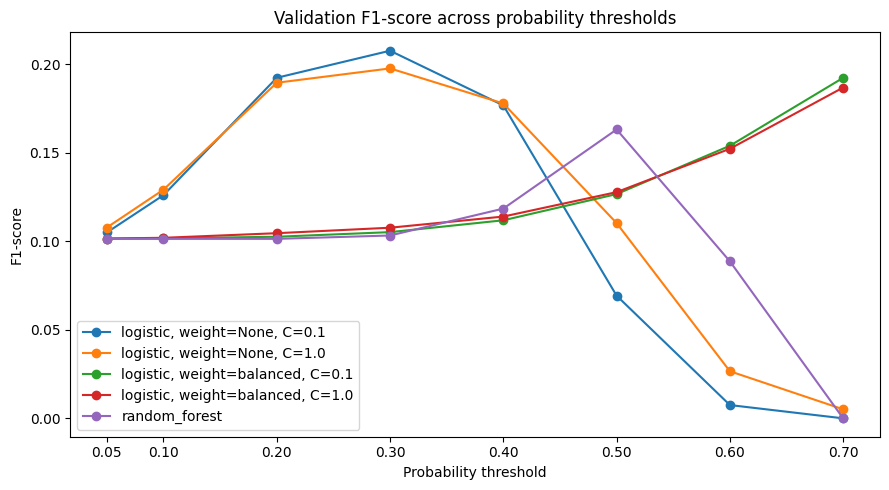

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for (model_type, class_weight, c_value), model in trained_models.items():
    probabilities = model.predict_proba(X_validation)[:, 1]
    curve_rows = [
        metrics_at_threshold(y_validation, probabilities, threshold)
        for threshold in thresholds
    ]
    curve = pd.DataFrame(curve_rows)
    if model_type == "random_forest":
        label = "random_forest"
    else:
        label = f"logistic, weight={class_weight}, C={c_value}"
    ax.plot(curve["threshold"], curve["f1"], marker="o", label=label)

ax.set_title("Validation F1-score across probability thresholds")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("F1-score")
ax.set_xticks(thresholds)
ax.legend()
plt.tight_layout()
plt.show()
fig.savefig(CHARTS_DIR / "06_validation_thresholds.png", dpi=150, bbox_inches="tight")


## 7. Select the model and threshold using validation F1

The selection rule is explicit: choose the row with the highest validation F1-score; use recall and precision as tie-breakers. This avoids choosing a model only because it predicts nearly every order as late.


In [7]:
best_row = comparison_table.iloc[0]
selected_model_type = best_row["model_type"]
selected_weight = None if best_row["class_weight"] == "None" else best_row["class_weight"]
selected_c = float(best_row["C"])
selected_threshold = float(best_row["threshold"])
selected_model = trained_models[(selected_model_type, selected_weight, selected_c)]

print(f"Selected model type: {selected_model_type}")
print(f"Selected class_weight: {selected_weight}")
print(f"Selected C: {selected_c}")
print(f"Selected threshold: {selected_threshold}")
print("Selected validation metrics:")
display(best_row.to_frame().T)


Selected model type: logistic
Selected class_weight: None
Selected C: 0.1
Selected threshold: 0.3
Selected validation metrics:


,threshold,accuracy,precision,recall,f1,model_type,class_weight,C
0,0.3,0.8698,0.1539,0.3195,0.2077,logistic,None,0.1


## 8. Evaluate once on the untouched test split


In [8]:
test_probabilities = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype("int8")

test_metrics = {
    "threshold": selected_threshold,
    "accuracy": round(float(accuracy_score(y_test, test_predictions)), 4),
    "precision": round(float(precision_score(y_test, test_predictions, zero_division=0)), 4),
    "recall": round(float(recall_score(y_test, test_predictions, zero_division=0)), 4),
    "f1": round(float(f1_score(y_test, test_predictions, zero_division=0)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, test_probabilities)), 4),
    "pr_auc": round(float(average_precision_score(y_test, test_probabilities)), 4),
}

print("Final test metrics:")
display(pd.DataFrame([test_metrics], index=["selected_model"]))
print(classification_report(
    y_test,
    test_predictions,
    target_names=["on_time", "late"],
    zero_division=0,
))


Final test metrics:


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
selected_model,0.3,0.6649,0.0936,0.4681,0.156,0.6451,0.108


              precision    recall  f1-score   support

     on_time       0.95      0.68      0.79     13514
        late       0.09      0.47      0.16       957

    accuracy                           0.66     14471
   macro avg       0.52      0.57      0.47     14471
weighted avg       0.89      0.66      0.75     14471



## 9. Plot the final test confusion matrix


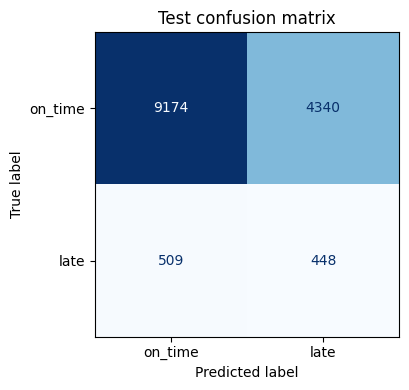

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["on_time", "late"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Test confusion matrix")
plt.tight_layout()
plt.show()
fig.savefig(CHARTS_DIR / "06_confusion_matrix.png", dpi=150, bbox_inches="tight")


## 10. Save the model and diagnostic results


In [10]:
model_path = MODELS_DIR / "06_model.joblib"
bundle_path = MODELS_DIR / "06_inference_bundle.joblib"
metadata_path = MODELS_DIR / "06_model_metadata.json"
preprocessor_path = FEATURES_DIR / "05_preprocessor.joblib"
feature_list_path = FEATURES_DIR / "05_feature_list.json"
feature_metadata_path = REPORTS_DIR / "05_feature_metadata.json"
results_path = REPORTS_DIR / "06_results.json"

joblib.dump(selected_model, model_path)
if not preprocessor_path.exists():
    preprocessor_path = FEATURES_DIR / "05_transformers.joblib"
preprocessor = joblib.load(preprocessor_path)
feature_names = json.loads(feature_list_path.read_text(encoding="utf-8"))
feature_metadata = json.loads(feature_metadata_path.read_text(encoding="utf-8"))
inference_bundle = {
    "model": selected_model,
    "preprocessor": preprocessor,
    "feature_names": feature_names,
    "threshold": selected_threshold,
    "model_name": "olist-late-delivery",
    "model_version": "task2-v1",
    "feature_metadata": feature_metadata,
}
joblib.dump(inference_bundle, bundle_path)

results = {
    "baseline_validation": baseline_metrics,
    "validation_comparison": comparison_table.to_dict(orient="records"),
    "selected_model": selected_model_type,
    "selected_class_weight": selected_weight,
    "selected_C": selected_c,
    "selected_threshold": selected_threshold,
    "selection_metric": "validation_f1",
    "test_metrics": test_metrics,
}
results_path.write_text(json.dumps(results, indent=2), encoding="utf-8")

metadata = {
    "model_name": "olist-late-delivery",
    "model_version": "task2-v1",
    "model_type": selected_model_type,
    "class_weight": selected_weight,
    "C": selected_c,
    "threshold": selected_threshold,
    "feature_count": len(feature_names),
    "selection_metric": "validation_f1",
    "test_metrics": test_metrics,
    "inference_bundle": bundle_path.name,
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved model to: {model_path}")
print(f"Saved inference bundle to: {bundle_path}")
print(f"Saved model metadata to: {metadata_path}")
print(f"Saved results to: {results_path}")


Saved model to: C:\Users\HP\Desktop\MLOps\Task2\artifacts\models\06_model.joblib
Saved inference bundle to: C:\Users\HP\Desktop\MLOps\Task2\artifacts\models\06_inference_bundle.joblib
Saved model metadata to: C:\Users\HP\Desktop\MLOps\Task2\artifacts\models\06_model_metadata.json
Saved results to: C:\Users\HP\Desktop\MLOps\Task2\artifacts\reports\06_results.json


## 11. Final checks


In [11]:
assert len(test_predictions) == len(y_test)
assert set(test_predictions).issubset({0, 1})
assert 0 < selected_threshold < 1
assert selected_model_type in {"logistic", "random_forest"}
assert model_path.exists() and model_path.stat().st_size > 0
assert bundle_path.exists() and bundle_path.stat().st_size > 0
assert metadata_path.exists() and metadata_path.stat().st_size > 0
assert results_path.exists() and results_path.stat().st_size > 0
assert (CHARTS_DIR / "06_validation_thresholds.png").exists()
assert (CHARTS_DIR / "06_confusion_matrix.png").exists()
print("ALL NOTEBOOK 6 DIAGNOSTIC CHECKS PASSED")


ALL NOTEBOOK 6 DIAGNOSTIC CHECKS PASSED
